# Predicting Business Credit Applicants (Universal Plus)

MSc Business Analytics, Analytics in Practice group project (Group 33). A CRISP-DM approach to identifying existing customers who are likely to apply for business credit.

*The dataset is confidential coursework data and isn't included, so the notebook is shown with its saved outputs.*

## Data Preparation and Cleaning

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [2]:
#Load the full dataset
df = pd.read_csv("data/datafile_full.csv"  # dataset not included in this repository (confidential coursework data))
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,125172.0,0,10.6216,0.1667,15.5182,10.1634,9.8419,-0.1156,7.4348,14.6948,...,2.8498,2.6391,1.2207,9.2747,22.3657,-0.4631,-3.1550,8.7551,15.9985,-10.4585
1,93976.0,0,13.1492,2.9210,6.0275,5.7623,12.5731,7.9090,5.3149,17.8441,...,9.1415,6.6176,2.6736,1.4019,17.5274,0.8023,-1.9248,7.5983,19.4170,-0.8740
2,128558.0,0,7.9077,4.3397,8.5575,4.7743,10.3623,-6.6784,5.9665,17.2378,...,6.9435,9.1727,0.2197,3.7017,17.7719,-0.8418,5.6689,9.1611,16.0874,-20.2895
3,138582.0,0,6.1757,-1.5021,16.5598,8.9091,8.0741,5.4070,5.3698,10.8735,...,5.6109,6.4601,0.6941,1.9114,19.0942,0.6026,8.6251,9.3223,14.9434,-13.8717
4,109242.0,0,10.6910,-6.5074,11.0558,4.4293,8.7645,-15.5975,5.6018,20.1398,...,-2.3920,11.2617,1.6179,11.2651,12.0931,-1.1808,7.2005,8.7301,14.8803,4.5960


In [3]:
# Shape of the dataset
print("Dataset shape:", df.shape)

Dataset shape: (100000, 202)


In [4]:
print("\nInfo:")
print(df.info())


Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 202 entries, ID_code to var_199
dtypes: float64(201), int64(1)
memory usage: 154.1 MB
None


In [5]:
print("\nSummary statistics:")
display(df.describe())


Summary statistics:


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,100000.000000,100000.000000,100000.000000,99998.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,99998.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,99916.419220,0.100380,10.681089,-1.645731,10.717789,6.794885,11.079585,-5.109574,5.407456,16.539886,...,3.233243,7.427054,1.926366,3.331256,17.998663,-0.144302,2.288391,8.908459,15.870637,-3.319631
std,57689.007176,0.300508,3.042589,4.057037,2.642314,2.038891,1.619818,7.885801,0.866186,3.409722,...,4.565283,3.022798,1.473717,3.989365,3.138752,1.431925,5.451997,0.922113,3.014117,10.431534
min,2.000000,0.000000,0.408400,-14.091000,2.117100,0.016200,5.074800,-30.681600,2.495700,5.349700,...,-13.999500,-2.343000,-3.566800,-11.783400,8.694400,-5.048100,-14.209600,6.119000,6.299300,-38.852800
25%,49950.750000,0.000000,8.461025,-4.776975,8.723400,5.259000,9.887300,-11.263775,4.764800,13.950100,...,-0.064500,5.151075,0.892300,0.597825,15.633175,-1.177200,-1.952500,8.252900,13.827275,-11.188675
50%,99884.500000,0.000000,10.533900,-1.623700,10.589800,6.820200,11.115850,-4.884250,5.383700,16.430900,...,3.205800,7.333800,1.901300,3.393750,17.973400,-0.171750,2.395800,8.889150,15.926950,-2.788150
75%,149756.500000,0.000000,12.754825,1.355375,12.516925,8.319900,12.263300,0.908975,6.001200,19.092975,...,6.410975,9.502425,2.941850,6.194950,20.400900,0.832700,6.544500,9.592900,18.066025,4.839125
max,200000.000000,1.000000,19.737900,10.376800,19.353000,13.188300,16.671400,16.781200,8.433000,27.691800,...,18.078900,16.520500,8.402400,17.908600,27.597300,4.272900,18.321500,11.953400,26.079100,27.534000


Several features have fewer than 100,000 values in the summary, meaning some missing values exist. We will handle this with median imputation

In [6]:
print("\nTarget distribution (counts):")
print(df['target'].value_counts())


Target distribution (counts):
target
0    89962
1    10038
Name: count, dtype: int64


In [7]:
print("\nTarget distribution (%):")
print(df['target'].value_counts(normalize=True) * 100)


Target distribution (%):
target
0    89.962
1    10.038
Name: proportion, dtype: float64


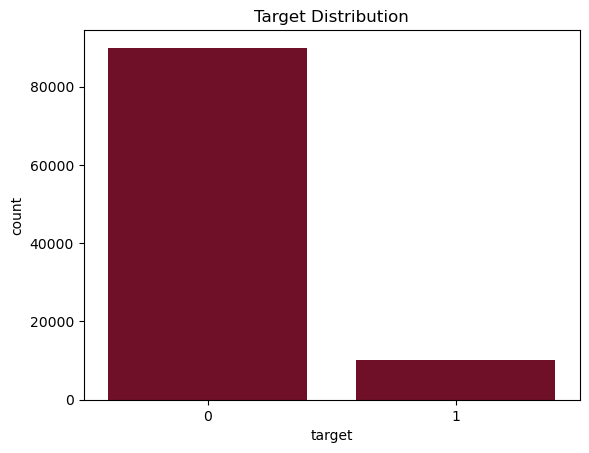

In [8]:
sns.countplot(x='target', data=df, color='#800020')
plt.title("Target Distribution")
plt.show()

This is a highly imbalanced dataset which is important information for SMOTE, evaluation metrics (ROC-AUC, recall, precision), and modelling choices.

In [9]:
#Separate features (X) and target (y)

# Drop ID_code since it is just an identifier
X = df.drop(columns=['ID_code', 'target'])
y = df['target']

print("X shape:", X.shape)
print("y shape:", y.shape)

# Check first few values
X.head(), y.head()

X shape: (100000, 200)
y shape: (100000,)


(     var_0   var_1    var_2    var_3    var_4    var_5   var_6    var_7  \
 0  10.6216  0.1667  15.5182  10.1634   9.8419  -0.1156  7.4348  14.6948   
 1  13.1492  2.9210   6.0275   5.7623  12.5731   7.9090  5.3149  17.8441   
 2   7.9077  4.3397   8.5575   4.7743  10.3623  -6.6784  5.9665  17.2378   
 3   6.1757 -1.5021  16.5598   8.9091   8.0741   5.4070  5.3698  10.8735   
 4  10.6910 -6.5074  11.0558   4.4293   8.7645 -15.5975  5.6018  20.1398   
 
     var_8   var_9  ...  var_190  var_191  var_192  var_193  var_194  var_195  \
 0 -2.6715  7.6273  ...   2.8498   2.6391   1.2207   9.2747  22.3657  -0.4631   
 1  5.7944  8.2108  ...   9.1415   6.6176   2.6736   1.4019  17.5274   0.8023   
 2 -5.3034  7.9590  ...   6.9435   9.1727   0.2197   3.7017  17.7719  -0.8418   
 3  0.9246  7.0595  ...   5.6109   6.4601   0.6941   1.9114  19.0942   0.6026   
 4 -1.4533  8.9974  ...  -2.3920  11.2617   1.6179  11.2651  12.0931  -1.1808   
 
    var_196  var_197  var_198  var_199  
 0  -3.1550  

In [10]:
#Train/Test Split (stratified)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=11,
    stratify=y   # VERY important due to imbalance
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

print("\nTarget distribution in training (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTarget distribution in test (%):")
print(y_test.value_counts(normalize=True) * 100)

Training set size: (70000, 200)
Test set size: (30000, 200)

Target distribution in training (%):
target
0    89.961429
1    10.038571
Name: proportion, dtype: float64

Target distribution in test (%):
target
0    89.963333
1    10.036667
Name: proportion, dtype: float64


This step helps ensure fair evaluation, maintains class imbalance ratio in both sets, and prevents data leakage.

In [11]:
#Median imputation for missing values

imputer = SimpleImputer(strategy='median')

# Fit on training data only
X_train_imputed = imputer.fit_transform(X_train)

# Transform both train and test
X_test_imputed = imputer.transform(X_test)

print("Imputation completed.")
print("Shapes after imputation:", X_train_imputed.shape, X_test_imputed.shape)

Imputation completed.
Shapes after imputation: (70000, 200) (30000, 200)


Median imputation handles outliers better than mean and avoids dropping rows which is important in imbalanced datasets.

In [12]:
#Scaling (only for LR and SVM)

scaler = StandardScaler()

# Fit scaler on training-imputed data only
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Tree-based models use imputed but unscaled data
X_train_tree = X_train_imputed
X_test_tree = X_test_imputed

print("Scaling completed.")
print("Scaled shapes:", X_train_scaled.shape, X_test_scaled.shape)

Scaling completed.
Scaled shapes: (70000, 200) (30000, 200)


SVM and Logistic Regression assume all features are on similar scales. Scaling prevents large-value features from dominating the model. Decision Trees and Random Forests must NOT be scaled — scaling makes no difference to them.

## Decision Tree

In [13]:
# Decision Tree (baseline model)

dt_model = DecisionTreeClassifier(
    criterion='gini',         
    max_depth=None,           
    random_state=11
)

# Train the model
dt_model.fit(X_train_tree, y_train)

print("Decision Tree model trained.")

Decision Tree model trained.


Confusion Matrix (Decision Tree_0):
[[24472  2517]
 [ 2400   611]]

Classification Report (Decision Tree_0):
              precision    recall  f1-score   support

           0       0.91      0.91      0.91     26989
           1       0.20      0.20      0.20      3011

    accuracy                           0.84     30000
   macro avg       0.55      0.55      0.55     30000
weighted avg       0.84      0.84      0.84     30000

Decision Tree Accuracy: 0.8361


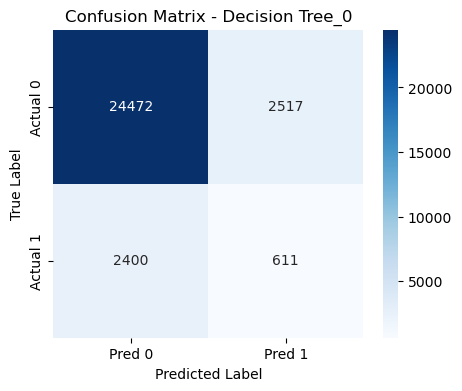

In [14]:
# Evaluate the Decision Tree

# Predictions
dt_pred = dt_model.predict(X_test_tree)

# Confusion matrix
cm_dt = confusion_matrix(y_test, dt_pred)
print("Confusion Matrix (Decision Tree_0):")
print(cm_dt)

# Classification report
print("\nClassification Report (Decision Tree_0):")
print(classification_report(y_test, dt_pred))

# Accuracy
dt_accuracy = dt_model.score(X_test_tree, y_test)
print("Decision Tree Accuracy:", dt_accuracy)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Decision Tree_0")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Because the dataset is highly imbalanced (only ~10% positive), Accuracy is 0.8361 but accuracy is misleading here because ~90% of customers are class 0 and a model that predicts everything as 0 would already achieve ~90% accuracy. 

For class 1:
- Precision = 0.20 → only 20% of predicted positives are correct
- Recall = 0.20 → only 20% of true positives are found
- F1 = 0.20 → very poor

The Decision Tree model shows high overall accuracy (0.84) and performs well in identifying the majority class (Class 0), with both precision and recall at 0.91. However, the performance for the minority class (Class 1) is very weak, with only 0.20 recall and 0.20 precision. This means the model misses 80% of the actual Class 1 cases, which directly conflicts with the business objective of accurately identifying customers who are likely to apply for credit (Class 1).

## Logistic Regression

In [15]:
#Logistic Regression (with balanced class weights)

logreg_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',  # important due to imbalance
    random_state=11
)

# Train on scaled training data
logreg_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained.")

Logistic Regression model trained.


Confusion Matrix (Logistic Regression):
[[21285  5704]
 [  701  2310]]

Classification Report (Logistic Regression):
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     26989
           1       0.29      0.77      0.42      3011

    accuracy                           0.79     30000
   macro avg       0.63      0.78      0.64     30000
weighted avg       0.90      0.79      0.82     30000

Logistic Regression Accuracy: 0.7865


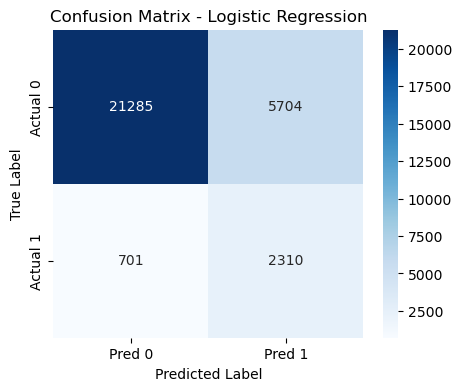

In [16]:
#Evaluate Logistic Regression

# Predictions for classes
lr_pred = logreg_model.predict(X_test_scaled)

# Confusion matrix
cm_lr = confusion_matrix(y_test, lr_pred)
print("Confusion Matrix (Logistic Regression):")
print(cm_lr)

# Classification report
print("\nClassification Report (Logistic Regression):")
print(classification_report(y_test, lr_pred))

# Accuracy
lr_accuracy = logreg_model.score(X_test_scaled, y_test)
print("Logistic Regression Accuracy:", lr_accuracy)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

The Logistic Regression model performed much better than the Decision Tree for identifying customers likely to apply for business credit. Even though the accuracy (78%) is slightly lower than the Decision Tree, the model does a much better job at finding the minority class. The recall for class 1 increased from 20% to 77%, meaning the model correctly identifies most real credit applicants. Precision for class 1 is lower (29%), but this is acceptable because the goal of the bank is to avoid missing potential applicants. Overall, Logistic Regression is a stronger model for this business problem because it balances the classes better and detects many more true positive customers.

## Apply selected features and using SMOTE to Logistic Regression Model

In [38]:
# Impute training data BEFORE computing mutual information
imputer_mi = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(imputer_mi.fit_transform(X_train), columns=X_train.columns)

# Compute MI scores
IG_scores = mutual_info_classif(X_train_imputed, y_train, random_state=11)

# Put into a dataframe
weights = pd.DataFrame({
    'attr_importance': IG_scores
}, index=X_train.columns)

# Select features above threshold
selected = weights[weights['attr_importance'] > 0.001]

# Extract final feature names
features = selected.index.tolist()

print(f"Number of selected features: {len(features)}")
print(f"Selected feature names:\n{features[:20]} ...")

Number of selected features: 85
Selected feature names:
['var_0', 'var_2', 'var_4', 'var_9', 'var_12', 'var_13', 'var_15', 'var_18', 'var_21', 'var_22', 'var_25', 'var_26', 'var_29', 'var_34', 'var_40', 'var_44', 'var_45', 'var_48', 'var_51', 'var_53'] ...


In [39]:
X_train_sel = X_train[features]
X_test_sel = X_test[features]

In [40]:
# Impute
imputer2 = SimpleImputer(strategy="median")
X_train_sel_imputed = pd.DataFrame(imputer2.fit_transform(X_train_sel), columns=X_train_sel.columns)
X_test_sel_imputed = pd.DataFrame(imputer2.transform(X_test_sel), columns=X_test_sel.columns)

# Scale
scaler_sel = StandardScaler()
X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel_imputed)
X_test_sel_scaled = scaler_sel.transform(X_test_sel_imputed)

# Train model
lr_sel = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=11)
lr_sel.fit(X_train_sel_scaled, y_train)

print("Model trained successfully.")

Model trained successfully.


Confusion Matrix (Selected Features):
[[20147  6842]
 [  832  2179]]

Classification Report (Selected Features):
              precision    recall  f1-score   support

           0       0.96      0.75      0.84     26989
           1       0.24      0.72      0.36      3011

    accuracy                           0.74     30000
   macro avg       0.60      0.74      0.60     30000
weighted avg       0.89      0.74      0.79     30000

Logistic Regression (Selected Features) Accuracy: 0.7442


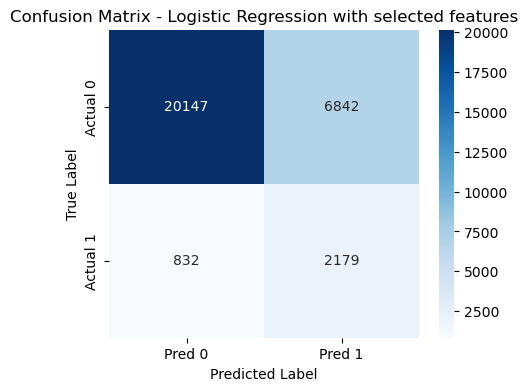

In [42]:
lr_sel_pred = lr_sel.predict(X_test_sel_scaled)
lr_sel_prob = lr_sel.predict_proba(X_test_sel_scaled)[:, 1]

print("Confusion Matrix (Selected Features):")
cm_lr_sel = confusion_matrix(y_test, lr_sel_pred)
print(cm_lr_sel)

print("\nClassification Report (Selected Features):")
print(classification_report(y_test, lr_sel_pred))

lr_sel_accuracy = lr_sel.score(X_test_sel_scaled, y_test)
print("Logistic Regression (Selected Features) Accuracy:", lr_sel_accuracy)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_lr_sel, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Logistic Regression with selected features")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

A second Logistic Regression model was trained using only the features selected through Information Gain (IG). However, this reduced-feature model performed worse across all evaluation metrics. Accuracy decreased from 0.786 to 0.74, and the recall for identifying future applicants fell from 0.77 to 0.72. Precision and F1-score were also lower. The selected-feature model additionally produced more false positives, making it less efficient for targeting customers. These results indicate that feature selection did not improve predictive performance; therefore, the full Logistic Regression model was retained as the final model.

In [21]:
# Import SMOTE
from imblearn.over_sampling import SMOTE

In [22]:
# Apply SMOTE to the training set
sm = SMOTE(random_state=11)
X_train_smote, y_train_smote = sm.fit_resample(X_train_imputed, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: target
0    62973
1     7027
Name: count, dtype: int64
After SMOTE: target
0    62973
1    62973
Name: count, dtype: int64


In [23]:
# Scale after SMOTE
scaler_sm = StandardScaler()
X_train_smote_scaled = scaler_sm.fit_transform(X_train_smote)
X_test_smote_scaled = scaler_sm.transform(X_test_imputed)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [24]:
# Train Logistic Regression with SMOTE data
logreg_smote = LogisticRegression(
    max_iter=1000,
    random_state=11
)

logreg_smote.fit(X_train_smote_scaled, y_train_smote)

print("Logistic Regression (SMOTE) trained.")


Logistic Regression (SMOTE) trained.


Confusion Matrix (LR + SMOTE):
[[21462  5527]
 [  745  2266]]

Classification Report (LR + SMOTE):
              precision    recall  f1-score   support

           0       0.97      0.80      0.87     26989
           1       0.29      0.75      0.42      3011

    accuracy                           0.79     30000
   macro avg       0.63      0.77      0.65     30000
weighted avg       0.90      0.79      0.83     30000

ROC-AUC (LR + SMOTE): 0.8543489045114374


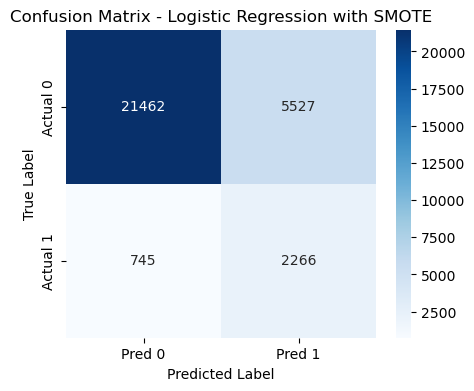

In [25]:
# Evaluate the Logistic Regression trained with SMOTE
lr_smote_pred = logreg_smote.predict(X_test_smote_scaled)

print("Confusion Matrix (LR + SMOTE):")
cm_lr_smote = confusion_matrix(y_test, lr_smote_pred)
print(cm_lr_smote)

print("\nClassification Report (LR + SMOTE):")
print(classification_report(y_test, lr_smote_pred))

# ROC-AUC
lr_smote_probs = logreg_smote.predict_proba(X_test_smote_scaled)[:, 1]
lr_smote_auc = roc_auc_score(y_test, lr_smote_probs)

print("ROC-AUC (LR + SMOTE):", lr_smote_auc)

# Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_lr_smote, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Logistic Regression with SMOTE")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Applying SMOTE to Logistic Regression produced very similar results to the original model. The recall for class 1 a bit lower from 0.77 to 0.75 and the precision and accuracy also stayed almost the same. This shows that Logistic Regression was already handling the class imbalance effectively using balanced class weights, and SMOTE did not provide any major improvement. For this reason, the original Logistic Regression model remains our preferred choice.

## Random Forest

In [26]:
# Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=None,         # allow full depth
    class_weight='balanced', # handle imbalance
    random_state=11
)

# Train on imputed (not scaled) data
rf_model.fit(X_train_tree, y_train)

print("Random Forest model trained.")

Random Forest model trained.


Confusion Matrix (Random Forest_0):
[[26989     0]
 [ 3011     0]]

Classification Report (Random Forest_0):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     26989
           1       0.00      0.00      0.00      3011

    accuracy                           0.90     30000
   macro avg       0.45      0.50      0.47     30000
weighted avg       0.81      0.90      0.85     30000



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Random Forest Accuracy: 0.8996333333333333


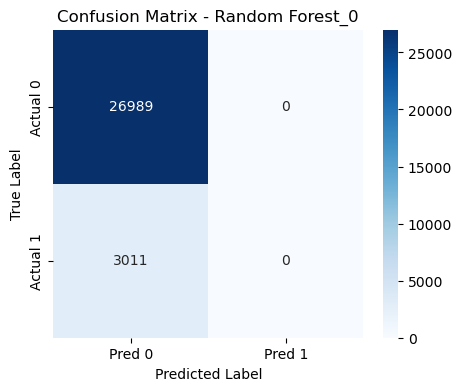

In [27]:
# Evaluate the Random Forest

# Predictions
rf_pred = rf_model.predict(X_test_tree)

# Confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)
print("Confusion Matrix (Random Forest_0):")
print(cm_rf)

# Classification report
print("\nClassification Report (Random Forest_0):")
print(classification_report(y_test, rf_pred))

# Accuracy
rf_accuracy = rf_model.score(X_test_tree, y_test)
print("Random Forest Accuracy:", rf_accuracy)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Random Forest_0")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

During evaluation, the Random Forest model produced warnings indicating that precision was “ill-defined” for the positive class. This occurred because the model failed to predict a single customer as class 1 (i.e., a future credit applicant). With no predicted positive cases, metrics such as precision, recall and F1-score for class 1 could not be computed and were therefore set to zero. Although the overall accuracy appeared high due to the large majority of class-0 customers, the model completely missed all true positive cases. This behaviour shows that the Random Forest is heavily biased toward the majority class and is unable to learn meaningful patterns about customers who apply for business credit. As a result, the model is not suitable for this task, and alternative models—such as Logistic Regression—provide far more useful predictive performance.

## Tuning the tree-based models (Finding max depth)

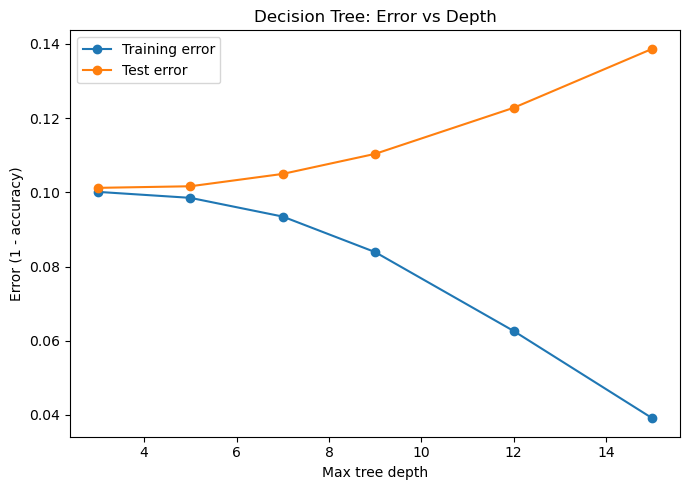

Best depth: 3
Best CV score: 0.8988142960810007


In [28]:
# define search space for max_depth
param_grid = {'max_depth': [3, 5, 7, 9, 12, 15]}

# create grid search object for cross-validation
grid = GridSearchCV(
    DecisionTreeClassifier(criterion='entropy', random_state=11),
    param_grid = param_grid,
    scoring = 'accuracy',
    cv = 3,
    return_train_score=True
)

# run the tuning
grid.fit(X_train_tree, y_train)

# extract and sort by depth
# grid.cv_results_ contains all results from the grid search
# we pull the max_depth values and the train/test scores for each depth

# take all max_depth values that were tested and turns them into a NumPy array
depths = np.array([int(d) for d in grid.cv_results_['param_max_depth']])

# find a sorting order for those depths (just to make sure they are ordered from small to large)
order = np.argsort(depths)

# rearrange depths in sorted order
depths = depths[order]

train_err = 1 - grid.cv_results_['mean_train_score'][order]
val_err   = 1 - grid.cv_results_['mean_test_score'][order]

# plot
plt.figure(figsize=(7,5))
plt.plot(depths, train_err, marker='o', label='Training error')
plt.plot(depths, val_err, marker='o', label='Test error')
plt.xlabel('Max tree depth')
plt.ylabel('Error (1 - accuracy)')
plt.title('Decision Tree: Error vs Depth')
plt.legend()
plt.tight_layout()
plt.show()

print("Best depth:", grid.best_params_['max_depth'])
print("Best CV score:", grid.best_score_)

This plot shows that as the tree depth increases, the training error decreases steadily, but the test error rises. This means the model is overfitting—deeper trees memorise the training data but perform worse on unseen data. The shallow trees (depth 3–5) generalise best, while deeper trees (10–15) become increasingly inaccurate on the test set.

Confusion Matrix (Random Forest_1):
[[20599  6390]
 [ 1081  1930]]

Classification Report (Random Forest_1):
              precision    recall  f1-score   support

           0       0.95      0.76      0.85     26989
           1       0.23      0.64      0.34      3011

    accuracy                           0.75     30000
   macro avg       0.59      0.70      0.59     30000
weighted avg       0.88      0.75      0.80     30000

Random Forest Accuracy: 0.7509666666666667


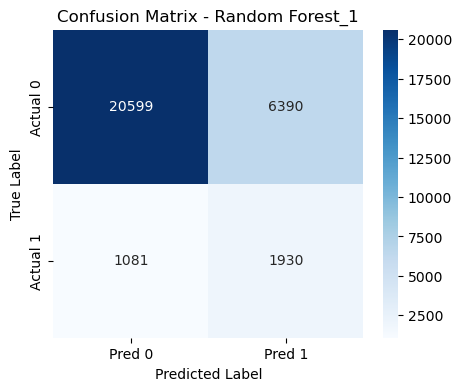

In [29]:
rf_model_2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    class_weight="balanced",
    random_state=11
)
rf_model_2.fit(X_train_tree, y_train)

# Predictions
rf_pred_2 = rf_model_2.predict(X_test_tree)

# Confusion matrix
cm_rf_2 = confusion_matrix(y_test, rf_pred_2)
print("Confusion Matrix (Random Forest_1):")
print(cm_rf_2)

# Classification report
print("\nClassification Report (Random Forest_1):")
print(classification_report(y_test, rf_pred_2))

# Accuracy
rf_accuracy_2 = rf_model_2.score(X_test_tree, y_test)
print("Random Forest Accuracy:", rf_accuracy_2)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_rf_2, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Random Forest_1")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Without any tuning, the baseline Random Forest model is highly overfitted to the majority class. The recall for the positive class increases from 0.00 to 0.64, meaning the model becomes much more capable of identifying actual applicants.Therefore, the tuned version of Random Forest provides more meaningful performance than the baseline model.

Decision Tree model trained.
Confusion Matrix (Decision Tree_1):
[[26984     5]
 [ 3005     6]]

Classification Report (Decision Tree_1):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     26989
           1       0.55      0.00      0.00      3011

    accuracy                           0.90     30000
   macro avg       0.72      0.50      0.48     30000
weighted avg       0.86      0.90      0.85     30000

Decision Tree Accuracy: 0.8996666666666666


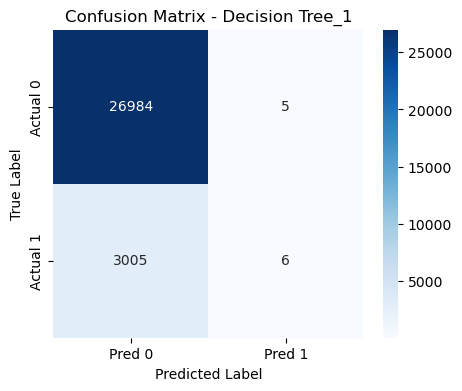

In [30]:
dt_model_2 = DecisionTreeClassifier(
    criterion='gini',         
    max_depth=3,           # allow full depth first
    random_state=11
)

# Train the model
dt_model_2.fit(X_train_tree, y_train)

print("Decision Tree model trained.")

# Predictions
dt_pred_2 = dt_model_2.predict(X_test_tree)

# Confusion matrix
cm_dt_2 = confusion_matrix(y_test, dt_pred_2)
print("Confusion Matrix (Decision Tree_1):")
print(cm_dt_2)

# Classification report
print("\nClassification Report (Decision Tree_1):")
print(classification_report(y_test, dt_pred_2))

# Accuracy
dt_accuracy_2 = dt_model_2.score(X_test_tree, y_test)
print("Decision Tree Accuracy:", dt_accuracy_2)

#Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm_dt_2, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - Decision Tree_1")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Due to the highly imbalanced nature of the dataset, the decision tree tends to classify almost all samples as the majority class (Class 0). Even after restricting the maximum depth to reduce overfitting, the model still fails to capture Class 1 instances, resulting in 0 recall and F1-score for the minority class. Therefore, tuning the depth does not make Decision Tree suitable for the business objective, which prioritises identifying Class 1 customers.

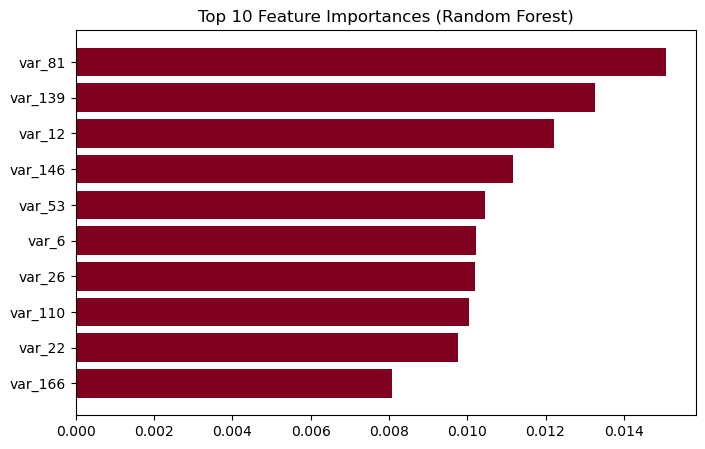

In [31]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-10:]  

plt.figure(figsize=(8,5))
plt.barh(range(len(indices)), importances[indices], color='#800020')
plt.yticks(range(len(indices)), np.array(X.columns)[indices])
plt.title("Top 10 Feature Importances (Random Forest)")
plt.show()

The Random Forest model identifies var_81, var_139, and var_12 as the most influential predictors, though all feature importances are relatively small. This suggests that the model relies on many weak but collectively useful signals rather than a few dominant features.

## SVM

In [32]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,                    
    class_weight="balanced",
    probability=True,          
    random_state=11
)

svm_model.fit(X_train_scaled, y_train)
print("SVM model trained successfully")

SVM model trained successfully


Confusion Matrix (SVM):
[[25156  1833]
 [ 1441  1570]]

Classification Report (SVM):
              precision    recall  f1-score   support

           0       0.95      0.93      0.94     26989
           1       0.46      0.52      0.49      3011

    accuracy                           0.89     30000
   macro avg       0.70      0.73      0.71     30000
weighted avg       0.90      0.89      0.89     30000

SVM Accuracy: 0.8908666666666667


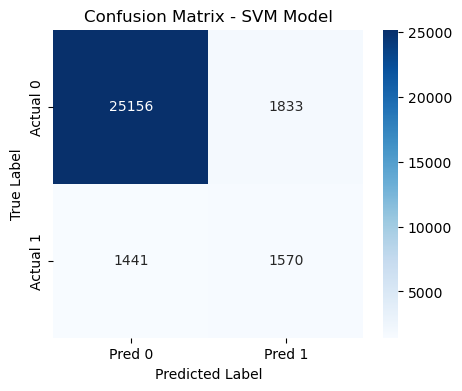

In [33]:
# Evaluate the SVM

# Predictions
svm_pred = svm_model.predict(X_test_scaled)
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

# Confusion matrix
cm_svm = confusion_matrix(y_test, svm_pred)
print("Confusion Matrix (SVM):")
print(cm_svm)

# Classification report
print("\nClassification Report (SVM):")
print(classification_report(y_test, svm_pred))

# Accuracy
svm_accuracy = svm_model.score(X_test_scaled, y_test)
print("SVM Accuracy:", svm_accuracy)

# Confusion Matrix Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_svm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix - SVM Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

The SVM model achieved strong overall performance, with an accuracy of 89%, but its ability to detect actual credit applicants remained moderate. The model correctly identified 52% of customers who went on to apply for business credit, which is a considerable improvement over tree-based models but still notably lower than the recall achieved by Logistic Regression. Although SVM performed very well on the majority class, correctly classifying 93% of non-applicants, this strength does not align with the primary business objective of minimising missed opportunities. The confusion matrix confirms that the model still fails to identify 1,441 true applicants, which represents a substantial loss of potential business engagement. Overall, while SVM is a competent classifier, its lower recall, slower training and testing time, and less favourable balance between identifying applicants and non-applicants make it less suitable than Logistic Regression for Universal Plus’s strategic needs.

## ROC Curve

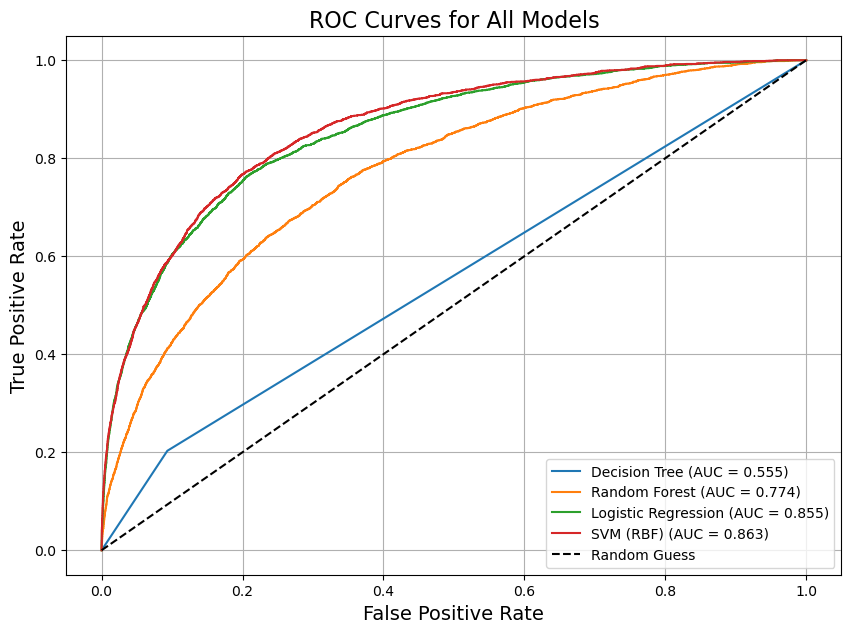

In [34]:
# 1. Decision Tree ROC
dt_probs = dt_model.predict_proba(X_test_tree)[:, 1]
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_probs)
dt_auc = roc_auc_score(y_test, dt_probs)

# 2. Random Forest ROC
rf_probs = rf_model_2.predict_proba(X_test_tree)[:, 1]
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

# 3. Logistic Regression ROC
lr_probs = logreg_model.predict_proba(X_test_scaled)[:, 1]
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
lr_auc = roc_auc_score(y_test, lr_probs)

# 4. SVM ROC (RBF kernel)
svm_probs = svm_model.predict_proba(X_test_scaled)[:, 1]
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_probs)
svm_auc = roc_auc_score(y_test, svm_probs)

# 5. Plot ROC Curves
plt.figure(figsize=(10, 7))
plt.plot(dt_fpr, dt_tpr, label=f"Decision Tree (AUC = {dt_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
plt.plot(svm_fpr, svm_tpr, label=f"SVM (RBF) (AUC = {svm_auc:.3f})")

# Chance line
plt.plot([0,1], [0,1], 'k--', label="Random Guess")

# Formatting
plt.title("ROC Curves for All Models", fontsize=16)
plt.xlabel("False Positive Rate", fontsize=14)
plt.ylabel("True Positive Rate", fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

The ROC curves show a clear performance ranking among the four models. Logistic Regression and the SVM (RBF kernel) demonstrate the strongest discriminative ability, with AUC scores of 0.855 and 0.863, respectively. These curves rise steeply toward the top-left corner, indicating that both models are highly effective at distinguishing between customers who will apply for business credit and those who will not. The SVM achieves the highest AUC overall, though the improvement over Logistic Regression is relatively small. In contrast, the Random Forest model performs moderately well (AUC 0.774), reflecting some predictive capability but noticeably weaker separation between classes. The Decision Tree shows the poorest performance (AUC 0.555), only marginally better than random guessing, highlighting its inability to generalise effectively in this high-dimensional, imbalanced dataset. Overall, the ROC analysis confirms Logistic Regression and SVM as the top-performing models, aligning with the project’s objective of reliably ranking customers by their likelihood to apply for business credit.

## Cumulative Gain Chart

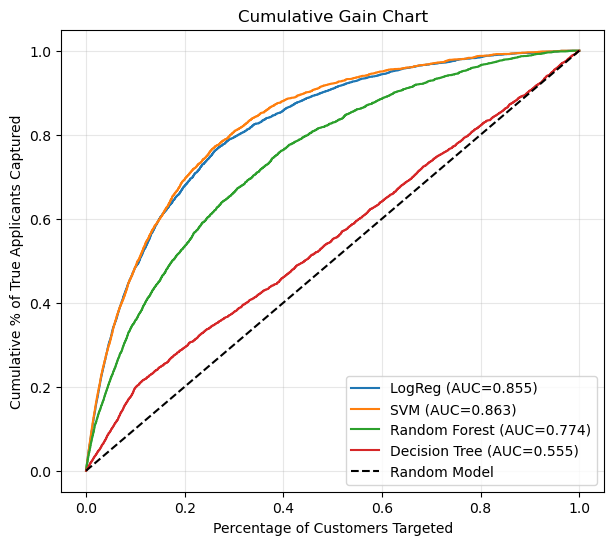

In [35]:
def cumulative_gain_curve(y_true, y_proba):
    y_true = np.asarray(y_true)  

    idx = np.argsort(y_proba)[::-1]
    y_sorted = y_true[idx]

    total_positives = y_true.sum()
    gains = np.cumsum(y_sorted) / total_positives
    percentages = np.arange(1, len(y_true)+1) / len(y_true)

    return percentages, gains


plt.figure(figsize=(7,6))

# Logistic Regression
pct_lr, gain_lr = cumulative_gain_curve(y_test, lr_probs)
plt.plot(pct_lr, gain_lr, label=f"LogReg (AUC={lr_auc:.3f})")

# SVM
pct_svm, gain_svm = cumulative_gain_curve(y_test, svm_probs)
plt.plot(pct_svm, gain_svm, label=f"SVM (AUC={svm_auc:.3f})")

# Random Forest
pct_rf, gain_rf = cumulative_gain_curve(y_test, rf_probs)
plt.plot(pct_rf, gain_rf, label=f"Random Forest (AUC={rf_auc:.3f})")

# Decision Tree
pct_dt, gain_dt = cumulative_gain_curve(y_test, dt_probs)
plt.plot(pct_dt, gain_dt, label=f"Decision Tree (AUC={dt_auc:.3f})")

# Random model benchmark
plt.plot([0,1],[0,1],'k--',label='Random Model')

plt.xlabel('Percentage of Customers Targeted')
plt.ylabel('Cumulative % of True Applicants Captured')
plt.title('Cumulative Gain Chart')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The cumulative gain chart highlights how effectively each model prioritises customers who are likely to apply for business credit. Both the SVM (AUC = 0.863) and Logistic Regression (AUC = 0.855) deliver the strongest gains, capturing a very large proportion of true applicants within the first 20–30% of customers targeted. This steep early lift is essential from a business perspective, as it shows that these models allow Universal Plus to focus outreach efforts on a small but highly responsive customer segment. In contrast, the Random Forest model performs moderately well but lags behind the top two models, while the Decision Tree provides only limited lift above a random selection strategy. Overall, the gain curves reinforce that Logistic Regression and SVM are far more effective at ranking customers by likelihood of application, enabling more efficient and cost-effective targeting strategies for Universal Plus.

## Precision and Recall Curves

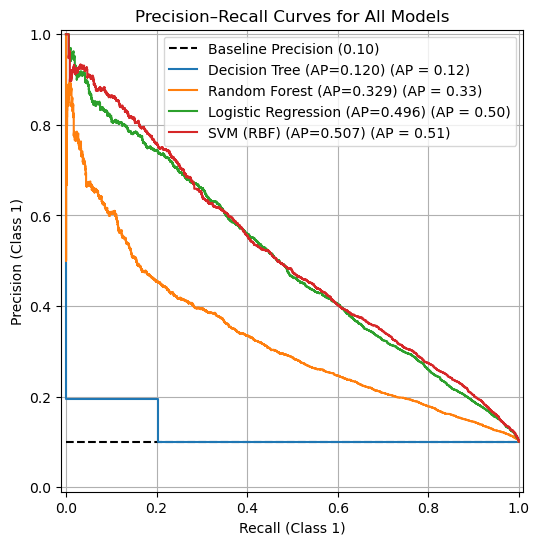

In [37]:
# Probabilities for each model
dt_probs  = dt_model.predict_proba(X_test_tree)[:, 1]
rf_probs  = rf_model_2.predict_proba(X_test_tree)[:, 1]
lr_probs  = logreg_model.predict_proba(X_test_scaled)[:, 1]
svm_probs = svm_model.predict_proba(X_test_scaled)[:, 1]  # probability=True enabled

models = {
    "Decision Tree": dt_probs,
    "Random Forest": rf_probs,
    "Logistic Regression": lr_probs,
    "SVM (RBF)": svm_probs
}

# Create single figure & axis 
plt.figure(figsize=(8, 6))
ax = plt.gca()

# Baseline precision (prevalence of class 1)
baseline = y_test.mean()
ax.hlines(
    baseline, 0, 1, colors="black", linestyles="--",
    label=f"Baseline Precision ({baseline:.2f})"
)

# Plot all PR curves on the SAME axis
for name, probs in models.items():
    ap = average_precision_score(y_test, probs)
    display = PrecisionRecallDisplay.from_predictions(
        y_test, probs, ax=ax, name=f"{name} (AP={ap:.3f})"
    )

# Formatting
ax.set_title("Precision–Recall Curves for All Models")
ax.set_xlabel("Recall (Class 1)")
ax.set_ylabel("Precision (Class 1)")
ax.grid(True)
ax.legend()
plt.show()

The Precision–Recall curve shows that Logistic Regression and SVM clearly outperform the tree-based models, maintaining much higher precision across different recall levels. Their average precision scores (≈0.50) indicate that they can identify true applicants far more effectively than Random Forest or Decision Tree, which stay close to the baseline. This confirms that the linear models provide the most reliable predictions for the imbalanced dataset, supporting the choice of Logistic Regression as the final model.

## 📌 Business Recommendations

1. Integrate the model into the CRM system
The logistic regression model can be embedded into Universal Plus’s customer management system to score customers weekly or monthly. This will allow the bank to proactively contact customers predicted to have high credit-application likelihood.

2. Prioritise outreach to high-scoring customers
Customers flagged by the model (top 5–10% probability) should be targeted with personalised communication, pre-approved credit offers and relationship-building activities.

3. Combine model scores with human expertise
Relationship managers should use model predictions alongside their own knowledge of client behaviour. The model should support, not replace, expert judgement.

4. Monitor model performance over time
Regular monitoring is needed to ensure the model continues to perform well. If applicant behaviour changes or new customer data becomes available, the model should be retrained.

5. Expand the model with additional data
If Universal Plus gains access to richer customer information (e.g., transaction categories, credit history, product usage), the model can be improved and extended.